#### Import Necessary libraries

In [24]:
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,roc_auc_score,roc_curve
import seaborn as sns
import matplotlib.pyplot as plt

#### Import Dataset

In [25]:
Social_Network_Ads = pd.read_csv("Social_Network_Ads.csv")
Social_Network_Ads

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


#### Data Understanding 

In [10]:
Social_Network_Ads.shape

(400, 5)

In [11]:
Social_Network_Ads.isna().sum()

User ID            0
Gender             0
Age                0
EstimatedSalary    0
Purchased          0
dtype: int64

In [12]:
Social_Network_Ads.dtypes

User ID             int64
Gender             object
Age                 int64
EstimatedSalary     int64
Purchased           int64
dtype: object

#### Data Preparation

In [13]:
X = Social_Network_Ads[["Age", "EstimatedSalary"]]
y = Social_Network_Ads["Purchased"]

#### Model Building

In [14]:
sc = StandardScaler()

X = sc.fit_transform(X)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



#### Model Training

In [15]:
Logistic_model = LogisticRegression()

Logistic_model.fit(X_train, y_train)

LogisticRegression()

#### Model Testing 

In [16]:
y_pred = Logistic_model.predict(X_test)
y_pred

array([0, 1, 0, 1, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 1, 0, 0,
       0, 1, 0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       1, 1, 0, 0, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0], dtype=int64)

#### Model Evaluation

In [22]:
print(confusion_matrix(y_test, y_pred))

[[50  2]
 [ 9 19]]


In [23]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.85      0.96      0.90        52
           1       0.90      0.68      0.78        28

    accuracy                           0.86        80
   macro avg       0.88      0.82      0.84        80
weighted avg       0.87      0.86      0.86        80



AUC Score: 0.820054945054945


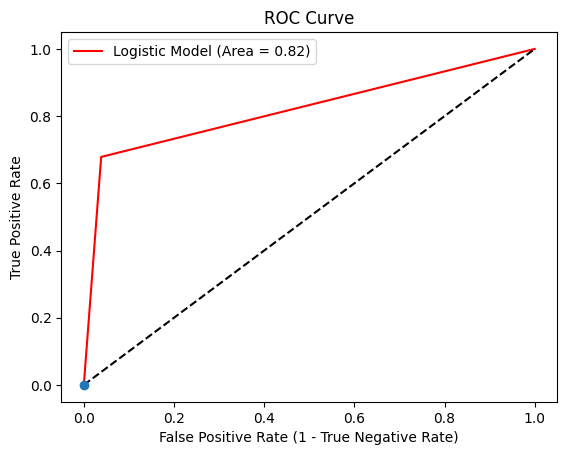

In [27]:
_pred_probability = Logistic_model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred)

auc = roc_auc_score(y_test, y_pred)

print("AUC Score:", auc)


plt.plot(fpr, tpr, color='red', label=f'Logistic Model (Area = {auc:.2f})')

plt.plot([0, 1], [0, 1], 'k--')

plt.plot(0, 0, 'o')

plt.xlabel('False Positive Rate (1 - True Negative Rate)')

plt.ylabel('True Positive Rate')

plt.title('ROC Curve')

plt.legend()

plt.show()